# Methods walkthrough: `RoyDGP` and the separate-approach MUO/MTO curves

This notebook mirrors the identification framework in
`docs/superpowers/specs/2026-07-19-mteo-design.md`: Kowalski (2023, *REStat*)
and Brinch, Mogstad & Wiswall (2017, *JPE*)'s binary-instrument MTE/MUO/MTO
setup. `mteo.dgp.RoyDGP` is a two-sided noncompliance Roy model with a known
polynomial MUO/MTO truth in `U ~ Uniform(0,1)`, so every estimate below can be
checked against a population value.

We walk through: (1) the default `extrapolation="none"` fit, which is
point-identified-only and refuses to guess beyond the complier range; (2)
`extrapolation="linear"` (Kowalski's AA.1 shape assumption), which unlocks
ATT/ATU/ATE and the Kowalski MUO/MTO figure; and (3) a deliberate
misspecification demo — fitting a linear curve to quadratic truth — showing
that the LATE (inside the identified range) stays honest while the
extrapolated ATE does not.


In [1]:
import mteo
from mteo.dgp import RoyDGP
import pandas as pd

dgp = RoyDGP(muo=(1.4, -0.8), mto=(2.0, -1.5), p_c=0.15, p_i=0.41, noise_sd=1.0)
df = dgp.sample(20_000, seed=0)
truth = dgp.truth()

display(df.head())

truth_table = pd.Series({
    "p_c": truth.p_c,
    "p_i": truth.p_i,
    "late": truth.late,
    "att": truth.att,
    "atu": truth.atu,
    "ate": truth.ate,
    "selection_stat": truth.selection_stat,
}, name="truth")
truth_table


,y,d,z
0,0.514933,0,1
1,0.165175,1,1
2,1.226753,1,0
3,0.877935,1,0
4,1.222091,0,1


p_c               0.1500
p_i               0.4100
late              0.4040
att               0.4565
atu               0.1975
ate               0.2500
selection_stat    0.3400
Name: truth, dtype: float64

In [2]:
# Default extrapolation="none": nothing beyond point identification.
result_none = mteo.fit(df, outcome="y", treatment="d", instrument="z",
                        extrapolation="none", bootstrap_reps=200, seed=0)
print(result_none.summary())


mteo fit summary
n = 20000   take-up: p_C = 0.148, p_I = 0.400 (gap 0.252)
shares: always 0.148 | compliers 0.252 | never 0.600

LATE = 0.4538 (SE 0.0608)
selection test (untreated, complier - never) = 0.2636 (SE 0.06108)
treated-outcome test = 0.4062 (SE 0.05532)
BMW Delta1-Delta0 = -0.1779 (SE 0.03917)
MTE slope = -1.413 (SE 0.3144)

LATE = 0.4538 (SE 0.0608)  [point]
ATT : not identified (requires MTE over (0.00, 0.40], beyond point identification; set extrapolation='linear' or 'bounds', or provide strata for more propensity points)
ATU : not identified (requires MTE over (0.15, 1.00], beyond point identification; set extrapolation='linear' or 'bounds', or provide strata for more propensity points)
ATE : not identified (requires MTE over (0.00, 1.00], beyond point identification; set extrapolation='linear' or 'bounds', or provide strata for more propensity points)


In [3]:
# ATT/ATU/ATE need AA.1 (linear) or bounds in a two-sided design; only LATE
# is point-identified from LATE assumptions alone. Confirm the statuses:
for k in ("late", "att", "atu", "ate"):
    e = result_none.estimands[k]
    print(f"{k:4s} status={e.status!r}  reason={e.reason!r}")


late status='point'  reason=''
att  status='not_identified'  reason="requires MTE over (0.00, 0.40], beyond point identification; set extrapolation='linear' or 'bounds', or provide strata for more propensity points"
atu  status='not_identified'  reason="requires MTE over (0.15, 1.00], beyond point identification; set extrapolation='linear' or 'bounds', or provide strata for more propensity points"
ate  status='not_identified'  reason="requires MTE over (0.00, 1.00], beyond point identification; set extrapolation='linear' or 'bounds', or provide strata for more propensity points"


<Axes: xlabel='p(U): percentile of net cost of treatment $U_D$', ylabel='outcome'>

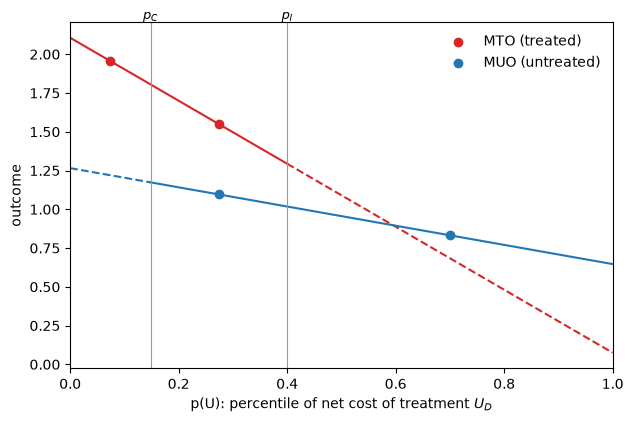

In [4]:
# Refit with extrapolation="linear" (Kowalski AA.1): unlocks ATT/ATU/ATE and
# lets us draw the full MUO/MTO curves, not just the identified cell means.
result_linear = mteo.fit(df, outcome="y", treatment="d", instrument="z",
                          extrapolation="linear", bootstrap_reps=200, seed=0)
result_linear.plot()


In [5]:
compare = pd.DataFrame({
    "estimate": {k: result_linear.estimands[k].value for k in ("late", "att", "atu", "ate")},
    "truth": {"late": truth.late, "att": truth.att, "atu": truth.atu, "ate": truth.ate},
})
compare["abs_diff"] = (compare["estimate"] - compare["truth"]).abs()
compare


,estimate,truth,abs_diff
late,0.453782,0.4040,0.049782
att,0.558390,0.4565,0.101890
atu,0.029935,0.1975,0.167565
ate,0.134543,0.2500,0.115457


In [6]:
# Honesty demo: quadratic MUO/MTO truth, but we fit a LINEAR (AA.1) curve.
# LATE lives inside the identified complier range and should stay close to
# truth; ATE is extrapolated off a misspecified linear curve and should not.
dgp_q = RoyDGP(muo=(1.0, 1.0, -2.0), mto=(2.0, -0.5, -1.0), p_c=0.2, p_i=0.5)
truth_q = dgp_q.truth()
df_q = dgp_q.sample(300_000, seed=21)

result_q = mteo.fit(df_q, outcome="y", treatment="d", instrument="z",
                     extrapolation="linear", bootstrap_reps=0)

honesty = pd.DataFrame({
    "estimate": {"late": result_q.estimands["late"].value, "ate": result_q.estimands["ate"].value},
    "truth": {"late": truth_q.late, "ate": truth_q.ate},
})
honesty["abs_diff"] = (honesty["estimate"] - honesty["truth"]).abs()
honesty


,estimate,truth,abs_diff
late,0.596305,0.605000,0.008695
ate,0.641555,0.583333,0.058222


## Takeaways

- `extrapolation="none"` is the safe default: LATE, group shares, and the
  untreated-outcome selection test are point-identified from LATE
  assumptions alone, with no functional-form assumption. ATT (two-sided),
  ATU, and ATE are reported `not_identified` rather than guessed.
- `extrapolation="linear"` (Kowalski's AA.1) is what unlocks ATT/ATU/ATE and
  the full MUO/MTO curves — but it is a real assumption, not a formality.
- The misspecification demo shows exactly what AA.1 buys and costs: LATE
  (inside the identified complier range) is essentially unaffected by getting
  the curve's shape wrong outside that range, while ATE (which requires
  extrapolating the linear fit across the full `U_D` support) can be
  materially wrong when the true MUO/MTO are not linear. Treat any
  `extrapolated` estimand as conditional on AA.1 holding on the extrapolated
  range — the package labels it `status="extrapolated"` precisely so this
  distinction is never silent.
